Doenc¸as cardiovasculares sao a principal causa de morte no mundo, respons ˜ aveis por cerca de 18 milh ´ oes de ˜ obitos ´
por ano segundo a OMS. O diagnostico precoce ´ e determinante para o sucesso do tratamento. Existe, portanto, uma ´
necessidade real de ferramentas capazes de estimar o risco de um paciente com base em dados cl´ınicos simples,
coletados em consulta de rotina. E nesse contexto que o aprendizado de m ´ aquina pode contribuir. Um modelo de ´
classificac¸ao treinado com dados hist ˜ oricos de pacientes diagnosticados ´ e capaz de aprender quais combinac¸ ´ oes de ˜
variaveis cl ´ ´ınicas estao associadas ˜ a presenc¸a de doenc¸a card ` ´ıaca e aplicar esse aprendizado a novos pacientes.
Neste projeto, voceˆ e convidado a construir um modelo utilizando regress ´ ao log ˜ ´ıstica para prever a presenc¸a de doenc¸a
card´ıaca com base em um conjunto de dados cl´ınicos.
O projeto utiliza o dataset Heart Disease Cleveland (UCI Machine Learning Repository – dispon´ıvel em https:
//archive.ics.uci.edu/dataset/45/heart+disease), com registros de 303 pacientes e 13 variaveis cl ´ ´ınicas.
Os diagnosticos foram confirmados por cateterismo card ´ ´ıaco, o que garante rotulos confi ´ aveis. As vari ´ aveis incluem: ´
• age — idade do paciente em anos;
• sex — sexo biologico (1 = masculino, 0 = feminino); ´
• cp — tipo de dor no peito: angina t´ıpica (1), at´ıpica (2), nao anginosa (3) ou assintom ˜ atico (4); ´
• trestbps — pressao arterial em repouso em mmHg; ˜
• chol — colesterol serico total em mg/dl; ´
• fbs — glicemia em jejum acima de 120 mg/dl (1 = sim, 0 = nao); ˜
• restecg — resultado do ECG em repouso: normal (0), alterac¸ao na onda ST-T (1) ou hipertrofia ventricular ˜
(2);
• thalach — frequencia card ˆ ´ıaca maxima atingida no teste de esforc¸o; ´
• exang — angina induzida por exerc´ıcio (1 = sim, 0 = nao); ˜
• oldpeak — depressao do segmento ST durante o esforc¸o, indicador de isquemia; ˜
• slope — inclinac¸ao do segmento ST no pico do esforc¸o: ascendente (1), plano (2) ou descendente (3); ˜
• ca — n´umero de arterias coron ´ arias com obstruc¸ ´ ao vis ˜ ´ıvel na fluoroscopia (0 a 3);
• thal — cintilografia de talio: normal (3), defeito fixo / infarto pr ´ evio (6) ou defeito revers ´ ´ıvel / isquemia ativa
(7);
A sa´ıda e a vari ´ avel ´ target, que indica o diagnostico original de 0 a 4, binarizado para 0 (sem doenc¸a) e 1 (com ´
doenc¸a) antes do treinamento.
Realize as seguintes tarefas utilizando o dataset fornecido:


Treinar um modelo de LogisticRegression do scikit-learn utilizando os dados de treino, com os seguintes parametros: ˆ solver=’liblinear’, random state=42 e max iter=1000. Indique quantas iterac¸oes ˜
foram necessarias para a converg ´ encia do modelo.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


colunas = [
    'age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 
    'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target'
]

dados = pd.read_csv(r'heart_disease\processed.cleveland.data', header=None, names=colunas, na_values='?')

dados.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [2]:
print("Faltantes por coluna:")
print(dados.isna().sum())

Faltantes por coluna:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64


In [3]:
print("Linhas com algum faltante:")
display(dados[dados.isna().any(axis=1)])

Linhas com algum faltante:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
87,53.0,0.0,3.0,128.0,216.0,0.0,2.0,115.0,0.0,0.0,1.0,0.0,NaN,0
166,52.0,1.0,3.0,138.0,223.0,0.0,0.0,169.0,0.0,0.0,1.0,NaN,3.0,0
192,43.0,1.0,4.0,132.0,247.0,1.0,2.0,143.0,1.0,0.1,2.0,NaN,7.0,1
266,52.0,1.0,4.0,128.0,204.0,1.0,0.0,156.0,1.0,1.0,2.0,0.0,NaN,2
287,58.0,1.0,2.0,125.0,220.0,0.0,0.0,144.0,0.0,0.4,2.0,NaN,7.0,0
302,38.0,1.0,3.0,138.0,175.0,0.0,0.0,173.0,0.0,0.0,1.0,NaN,3.0,0


In [4]:
len(dados)

303

In [5]:
from sklearn.impute import SimpleImputer

# Binarização do diagnóstico; a imputação será ajustada somente no treino.
dados["target"] = (dados["target"] > 0).astype(int)

In [6]:
print(f"Quantidade de amostras SEM doençe = {np.bincount(dados['target'])[0]}")
print(f"Quantidade de amostras C doença = {np.bincount(dados['target'])[1]}")

Quantidade de amostras SEM doençe = 164
Quantidade de amostras C doença = 139


In [7]:
x = dados.drop(columns=["target"])
print(x.columns)
y = dados[['target']]
print(y.columns)

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'ca', 'thal'],
      dtype='str')
Index(['target'], dtype='str')


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42
)

print(f"Treino: {X_train.shape[0]} amostras")
print(f"Teste:  {X_test.shape[0]} amostras")

Treino: 242 amostras
Teste:  61 amostras


In [9]:
imp = SimpleImputer(strategy="median")
X_train_imp = imp.fit_transform(X_train)
X_test_imp = imp.transform(X_test)

scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_imp)
X_test_sc  = scaler.transform(X_test_imp)

In [10]:
model = LogisticRegression(solver='liblinear', random_state=42, max_iter=1000)

model.fit(X_train_sc, y_train.values.ravel())
print(f"Iterações até a convergência: {model.n_iter_[0]}")

Iterações até a convergência: 6


In [11]:
y_pred = model.predict(X_test_sc)
y_prob = model.predict_proba(X_test_sc)[:, 1]

from sklearn.metrics import (
    confusion_matrix, roc_auc_score, roc_curve, accuracy_score, 
    precision_score, recall_score, f1_score
)

print(f"Acurácia: {accuracy_score(y_test, y_pred):.4f}")
print(f"Precisão: {precision_score(y_test, y_pred):.4f}")
print(f"Recall: {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score: {f1_score(y_test, y_pred):.4f}")

Acurácia: 0.8852
Precisão: 0.8788
Recall: 0.9062
F1-Score: 0.8923


AUC-ROC:  0.9213


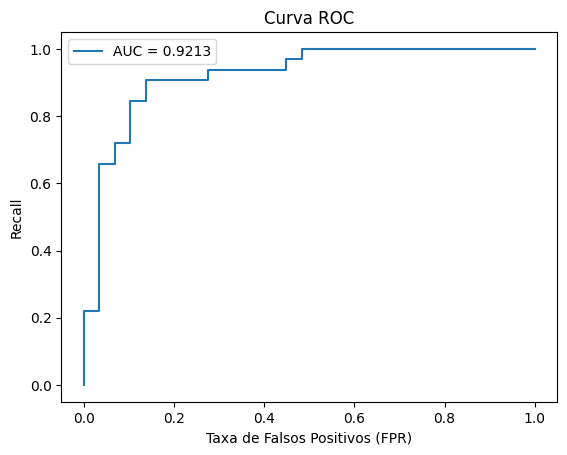

In [12]:
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)

print(f"AUC-ROC:  {roc_auc_score(y_test, y_prob):.4f}")

# Plotar
plt.plot(fpr, tpr, label=f'AUC = {auc:.4f}')
plt.xlabel('Taxa de Falsos Positivos (FPR)')
plt.ylabel('Recall')
plt.title('Curva ROC')
plt.legend()
plt.show()

In [13]:
print(confusion_matrix(y_test, y_pred))

[[25  4]
 [ 3 29]]
